Here is the problem text cleanly formatted in Markdown:

---

### **238. Product of Array Except Self**

**Status:** Solved | **Difficulty:** Medium

**Topics:** Array, Prefix Sum

---

Given an integer array `nums`, return an array `answer` such that `answer[i]` is equal to the product of all the elements of `nums` except `nums[i]`.

The product of any prefix or suffix of `nums` is guaranteed to fit in a 32-bit integer.

You must write an algorithm that runs in $O(n)$ time and without using the division operation.

---

### **Examples**

#### **Example 1:**

* **Input:** `nums = [1, 2, 3, 4]`
* **Output:** `[24, 12, 8, 6]`

#### **Example 2:**

* **Input:** `nums = [-1, 1, 0, -3, 3]`
* **Output:** `[0, 0, 9, 0, 0]`

---

### **Constraints:**

* $2 \le \text{nums.length} \le 10^5$
* $-30 \le \text{nums}[i] \le 30$
* The input is generated such that `answer[i]` is guaranteed to fit in a 32-bit integer.

---

### **Follow-up:**

Can you solve the problem in $O(1)$ extra space complexity? *(Note: The output array does not count as extra space for space complexity analysis.)*

In [2]:
def productExceptSelf(nums: list[int]) -> list[int]:
    ans=[1]*len(nums)

    prefix=1
    print("prefix")
    for i in range(len(nums)):
        print(ans[i],prefix)
        ans[i]=prefix
        prefix*=nums[i]

    suffix=1
    print("suffix")
    for i in range(len(nums)-1,-1,-1):
        print(ans[i], suffix)
        ans[i]*=suffix
        suffix*=nums[i]

    print(ans)

productExceptSelf([1,2,3,4])

prefix
1 1
1 1
1 2
1 6
suffix
6 1
2 4
1 12
1 24
[24, 12, 8, 6]


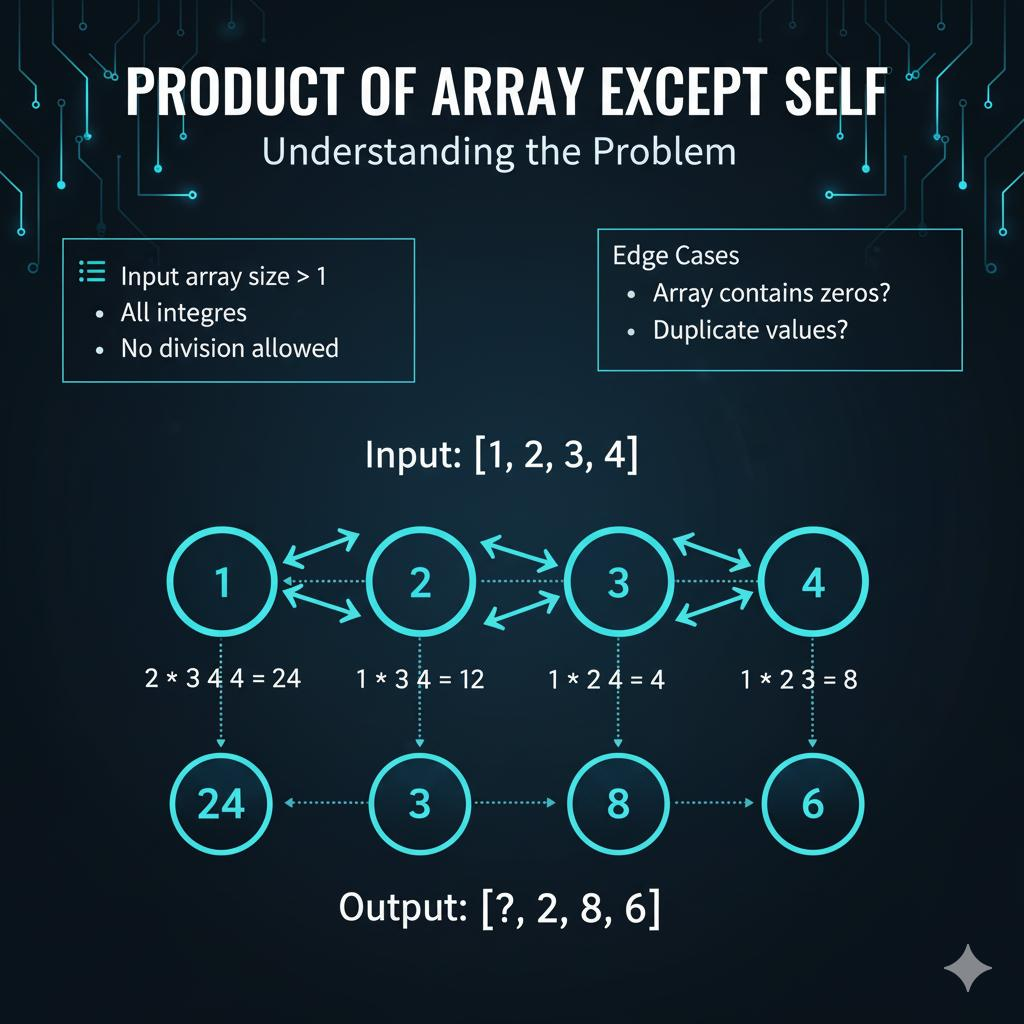

## Product of Array Except Self

**Product of Array Except Self** is LeetCode problem 238, a classic array problem asking for an output where each position contains the product of every input element except the one at that position. It is especially notable for its **O(n)** solution without division, using prefix and suffix products.







### Core idea

For an array `nums`, the answer at index `i` can be decomposed into **product of everything left of `i` × product of everything right of `i`**. For example, `[1, 2, 3, 4]` becomes `[24, 12, 8, 6]`: at index 2, the result is `(1×2) × 4 = 8`.

### The optimal approach

A first pass stores each index's **prefix product** directly in the output array. A second, right-to-left pass maintains a running **suffix product**, multiplies it into the existing prefix value, and then updates the suffix. This achieves **O(n) time** and **O(1) auxiliary space** when the required output array is excluded from the space count.

### Why division is avoided

Simply computing the total product and dividing by each element looks attractive, but the problem explicitly rules out division. More importantly, **zeros make division-based reasoning awkward**: prefix/suffix multiplication naturally handles one or multiple zeros without any special cases.

### Python implementation

```python
def productExceptSelf(nums):
    ans = [1] * len(nums)

    prefix = 1
    for i in range(len(nums)):
        ans[i] = prefix
        prefix *= nums[i]

    suffix = 1
    for i in range(len(nums) - 1, -1, -1):
        ans[i] *= suffix
        suffix *= nums[i]

    return ans
```

The key pattern is broader than this particular problem: **precompute information from the left, then combine it with information accumulated from the right**. Recognizing that prefix/suffix decomposition is often the main conceptual leap in solving problem 238 efficiently.